In [1]:
# Importaciones estándar para EDA
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yaml

# Función para cargar la configuración desde el YAML
def load_config(config_path="../config/config.yaml"):
    try:
        with open(config_path, "r", encoding="utf-8") as file:
            return yaml.safe_load(file)
    except FileNotFoundError:
        print(f"Error: No se encontró el config.yaml en {config_path}")
        return None

print("Librerías importadas correctamente. Listos para iniciar.")

Librerías importadas correctamente. Listos para iniciar.


In [3]:
# Cargar configuración
config = load_config()

# Extraer ruta y cargar DataFrame
ruta_bronze = "../" + config["sources"]["raw_airquality_data"]["path"]

if os.path.exists(ruta_bronze):
    df_raw = pd.read_csv(ruta_bronze)
    print(f"Dataset cargado con éxito. Dimensiones: {df_raw.shape[0]} filas y {df_raw.shape[1]} columnas.")
else:
    print(f"Error: No se encontró el archivo en la ruta {ruta_bronze}")

#Primeros datos del dataset crudo
display(df_raw.head())

Dataset cargado con éxito. Dimensiones: 23463 filas y 12 columnas.


,Country,City,AQI Value,AQI Category,CO AQI Value,CO AQI Category,Ozone AQI Value,Ozone AQI Category,NO2 AQI Value,NO2 AQI Category,PM2.5 AQI Value,PM2.5 AQI Category
0,Russian Federation,Praskoveya,51,Moderate,1,Good,36,Good,0,Good,51,Moderate
1,Brazil,Presidente Dutra,41,Good,1,Good,5,Good,1,Good,41,Good
2,Italy,Priolo Gargallo,66,Moderate,1,Good,39,Good,2,Good,66,Moderate
3,Poland,Przasnysz,34,Good,1,Good,34,Good,0,Good,20,Good
4,France,Punaauia,22,Good,0,Good,22,Good,0,Good,6,Good


--- CONTEO DE VALORES NULOS ---
Country    427
City         1
dtype: int64


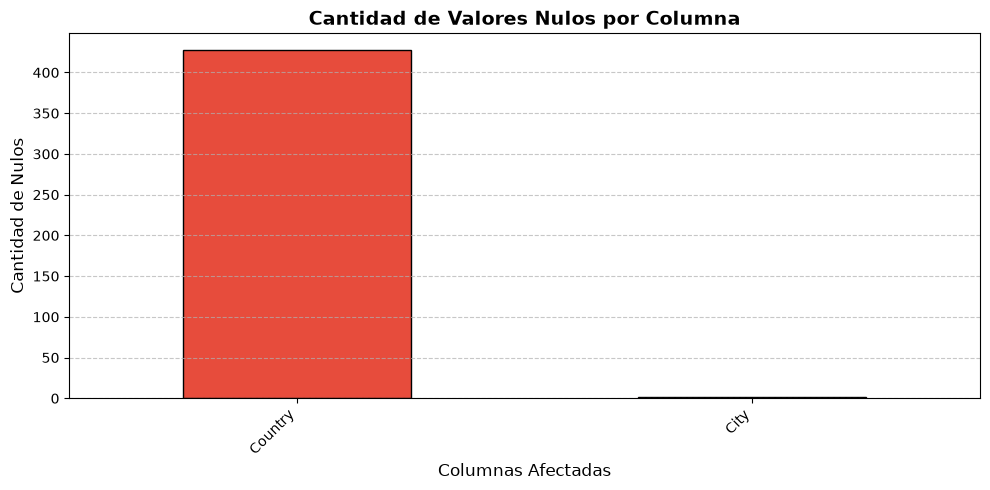

In [4]:
print("--- CONTEO DE VALORES NULOS ---")
nulos = df_raw.isnull().sum()
nulos_filtrados = nulos[nulos > 0]

if not nulos_filtrados.empty:
    print(nulos_filtrados)
    
    # Gráfico de barras usando solo matplotlib
    plt.figure(figsize=(10, 5))
    nulos_filtrados.sort_values(ascending=False).plot(kind='bar', color='#e74c3c', edgecolor='black')
    
    plt.title("Cantidad de Valores Nulos por Columna", fontsize=14, fontweight='bold')
    plt.ylabel("Cantidad de Nulos", fontsize=12)
    plt.xlabel("Columnas Afectadas", fontsize=12)
    plt.xticks(rotation=45, ha='right')
    
    # Agregar rejilla (grid) sutil para facilitar la lectura
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    
    plt.tight_layout()
    plt.show()
else:
    print("¡Genial! No se detectaron valores nulos en el dataset.")

In [5]:
print("--- 1. INFORMACIÓN GENERAL Y TIPOS DE DATOS ---")
# info() imprime directamente en consola
df_raw.info()

print("\n--- 2. BÚSQUEDA DE DUPLICADOS ---")
duplicados = df_raw.duplicated().sum()
print(f"Se encontraron {duplicados} filas exactamente duplicadas.")

if duplicados > 0:
    print("Muestra de duplicados:")
    display(df_raw[df_raw.duplicated(keep=False)].sort_values(by=list(df_raw.columns)).head())

--- 1. INFORMACIÓN GENERAL Y TIPOS DE DATOS ---
<class 'pandas.DataFrame'>
RangeIndex: 23463 entries, 0 to 23462
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Country             23036 non-null  str  
 1   City                23462 non-null  str  
 2   AQI Value           23463 non-null  int64
 3   AQI Category        23463 non-null  str  
 4   CO AQI Value        23463 non-null  int64
 5   CO AQI Category     23463 non-null  str  
 6   Ozone AQI Value     23463 non-null  int64
 7   Ozone AQI Category  23463 non-null  str  
 8   NO2 AQI Value       23463 non-null  int64
 9   NO2 AQI Category    23463 non-null  str  
 10  PM2.5 AQI Value     23463 non-null  int64
 11  PM2.5 AQI Category  23463 non-null  str  
dtypes: int64(5), str(7)
memory usage: 2.1 MB

--- 2. BÚSQUEDA DE DUPLICADOS ---
Se encontraron 0 filas exactamente duplicadas.


--- 3. ANÁLISIS ESTADÍSTICO Y OUTLIERS ---


/tmp/user/1000/ipykernel_21724/2954290911.py:10: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df_raw[columna_aqi].dropna(),


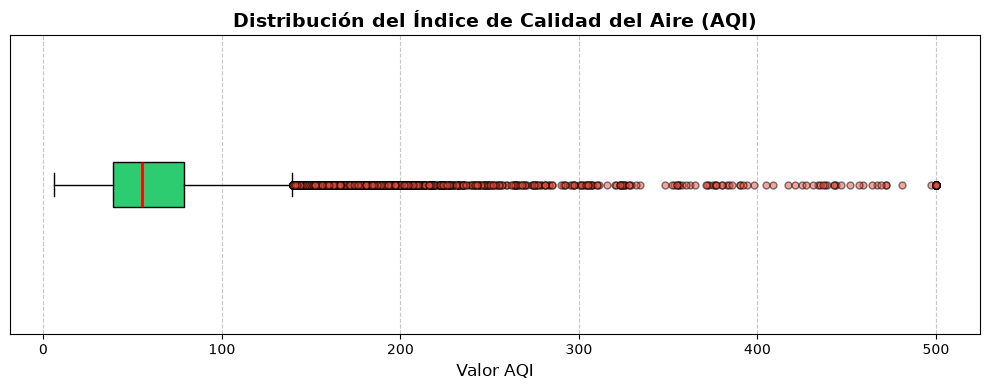


Resumen estadístico de 'AQI Value':
count    23463.000000
mean        72.010868
std         56.055220
min          6.000000
25%         39.000000
50%         55.000000
75%         79.000000
max        500.000000
Name: AQI Value, dtype: float64


In [6]:
print("--- 3. ANÁLISIS ESTADÍSTICO Y OUTLIERS ---")

# Busca el nombre exacto de la columna principal en el resultado del df.info()
columna_aqi = "AQI Value" 

if columna_aqi in df_raw.columns:
    plt.figure(figsize=(10, 4))
    
    # Boxplot horizontal
    plt.boxplot(df_raw[columna_aqi].dropna(), 
                vert=False, 
                patch_artist=True,
                boxprops=dict(facecolor='#2ecc71', color='black'),
                medianprops=dict(color='red', linewidth=2),
                flierprops=dict(marker='o', markerfacecolor='#e74c3c', markersize=5, alpha=0.5))
    
    plt.title("Distribución del Índice de Calidad del Aire (AQI)", fontsize=14, fontweight='bold')
    plt.xlabel("Valor AQI", fontsize=12)
    plt.yticks([]) 
    plt.grid(axis='x', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()
    
    # Resumen matemático
    print(f"\nResumen estadístico de '{columna_aqi}':")
    print(df_raw[columna_aqi].describe())
else:
    print(f"La columna '{columna_aqi}' no se encontró. Revisa los nombres en la celda anterior.")

In [7]:
print("--- 4. CONTEO EXACTO DE VALORES NULOS ---")
# 1. Contamos todos los nulos por columna
nulos = df_raw.isnull().sum()

# 2. Filtramos para ver SOLO las columnas que tienen al menos un nulo
columnas_con_nulos = nulos[nulos > 0]

# 3. Imprimimos el resultado
if not columnas_con_nulos.empty:
    print("Columnas que tienen datos faltantes:")
    print(columnas_con_nulos.sort_values(ascending=False))
    
    # Opcional: Mostrar el porcentaje que representan esos nulos
    print("\nPorcentaje de datos perdidos:")
    porcentaje = (columnas_con_nulos / len(df_raw)) * 100
    print(porcentaje.sort_values(ascending=False).round(2).astype(str) + ' %')
else:
    print("¡No hay ningún valor nulo en todo el dataset!")

--- 4. CONTEO EXACTO DE VALORES NULOS ---
Columnas que tienen datos faltantes:
Country    427
City         1
dtype: int64

Porcentaje de datos perdidos:
Country    1.82 %
City        0.0 %
dtype: str


In [8]:
# 1. Tu filtro se queda exactamente igual
resultado = df_raw.loc[df_raw['Country'].isna() | df_raw['City'].isna(), ['Country', 'City']]

# 2. Convertirlo a String obliga a la pantalla a renderizar TODO sin recortar
print(resultado.to_string())

      Country                        City
535       NaN                   Granville
654       NaN          Kingston Upon Hull
787       NaN               New Waterford
801       NaN                   Kingstown
906       NaN                    Nanakuli
916       NaN                     Lavagna
968       NaN                   Ladispoli
985       NaN                    Dong Hoi
1139      NaN                     Nettuno
1169      NaN                 Puebloviejo
1247      NaN                   Fiumicino
1474      NaN                 Nishinomiya
1550      NaN                    Carteret
1609      NaN                    Ercolano
1627      NaN                      Bolama
1631      NaN                     Bairiki
1693      NaN                      Broome
1712      NaN                    Cananeia
1723      NaN                      Cavite
1792      NaN               Prince Rupert
1824      NaN                      Roseau
1918      NaN                   Ardrossan
1958      NaN                   St